# Phase 2 · Model 2 · Encoder adapters for legal NER

The encoder and shared embeddings come from the Phase 1 encoder–decoder checkpoint. Training updates two bottleneck adapters per encoder block and the character head. The original encoder weights stay frozen.

The head uses masked character convolutions and a bidirectional layer. Overlapping windows recover document-level predictions with BIO Viterbi decoding.

## A1. Required files and environment

- Attach the completed Phase 1 `encoder_decoder_500m_batch4_trial` run with `best.pt`, `run_config.json`, and `tokenizer.json`.
- Attach `evaluate_phase2.py` and the official `Phase_2_LNER` dataset. Enable Internet and set `HF_TOKEN` or `HF` to download the dataset in Kaggle.
- Enable a GPU. Set `BASE_RUN` if multiple checkpoints are attached, `RESUME_DIR` to restore an existing run, or `REFERENCE_SPLIT` to verify the document split.

In [1]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','numpy','huggingface-hub','matplotlib'],check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy', 'huggingface-hub', 'matplotlib'], returncode=0)

In [2]:
import copy, gc, hashlib, heapq, json, math, os, random, re, shutil, time, zipfile
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from IPython.display import display, HTML

SOURCES = ('supreme_court', 'high_courts', 'acts', 'tribunals')
PAD, UNK, BOS, EOS = range(4)
VERSION = 'local-global-causal-v1'

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(tmp, path)

def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8 * 1024**2), b''): h.update(block)
    return h.hexdigest()

def atomic_save(value, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(value, str(path) + '.tmp')
    os.replace(str(path) + '.tmp', path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(),
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restore_rng(s):
    random.setstate(s['python']); np.random.set_state(s['numpy']); torch.set_rng_state(s['torch'])
    if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])

from collections import Counter
import bisect


In [3]:
INPUT_ROOT=Path('/kaggle/input')
BASE_RUN=None
BASE_CHECKPOINT=None
DATA_ROOT=None
EVALUATOR_PATH=None
RESUME_DIR=None
RUN_DIR=Path('/kaggle/working/phase2_model2_adapters')
ASSET_DIR=Path('/kaggle/working/phase2_model2_assets')
REPO='Exploration-Lab/CS-781-Capstone'
DATA_REVISION=None
REFERENCE_SPLIT=None
CONFIG=dict(seed=42,validation_fraction=0.15,window=1024,overlap=256,
    epochs=40,effective_batch=4,micro_batch=1,activation_checkpointing=True,
    adapter_lr=1e-4,head_lr=5e-4,min_lr_ratio=0.1,warmup_fraction=0.06,
    weight_decay=0.01,clip=1.0,eval_every=1000,save_every=100,log_every=20,
    class_weight_cap=5.0,head_dim=128,char_buckets=4096,adapter_dim=64,
    max_hours=10,head_version="encoder-adapters-bi-conv-v1",bi_dropout=0.1)
ASSET_DIR.mkdir(parents=True,exist_ok=True)
if BASE_RUN is None:
    candidates=[]
    for path in INPUT_ROOT.rglob('run_config.json'):
        cfg=read_json(path)
        if cfg.get('version')=='encdec-512w-128w-v1':
            candidates.append(path.parent)
    if len(candidates)!=1: raise ValueError(f'Set BASE_RUN to the Phase-1 model-2 folder. Found: {candidates}')
    BASE_RUN=candidates[0]
BASE_RUN=Path(BASE_RUN)
BASE_CHECKPOINT=Path(BASE_CHECKPOINT) if BASE_CHECKPOINT else BASE_RUN/'best.pt'
if EVALUATOR_PATH is None:
    candidates=list(INPUT_ROOT.rglob('evaluate_phase2.py'))
    if len(candidates)!=1: raise ValueError(f'Set EVALUATOR_PATH. Found: {candidates}')
    EVALUATOR_PATH=candidates[0]
EVALUATOR_PATH=Path(EVALUATOR_PATH)
if RESUME_DIR is not None:
    origin=Path(RESUME_DIR)
    if origin.resolve()!=RUN_DIR.resolve():
        if RUN_DIR.exists() and any(RUN_DIR.iterdir()): raise ValueError('Restore into an empty RUN_DIR')
        shutil.copytree(origin,RUN_DIR)
if (RUN_DIR/'config.json').is_file(): CONFIG=read_json(RUN_DIR/'config.json')['config']
print('Checkpoint:',BASE_CHECKPOINT)
print('Output:',RUN_DIR)


Checkpoint: /kaggle/input/datasets/acadsiitk/model2-phae2/best.pt
Output: /kaggle/working/phase2_model2_adapters


In [4]:
def get_data_root(explicit=None):
    needed=['Train/fold1-text.json','Train/fold1-gold.json','Train/fold2-text.json',
            'Train/fold2-gold.json','Train/labels.txt','Test/fold3-text.json']
    def valid(root): return all((root/p).is_file() for p in needed)
    if explicit is not None:
        root=Path(explicit)
        if not valid(root): raise FileNotFoundError(root)
        return root
    found=sorted({p.parent.parent for p in INPUT_ROOT.rglob('fold1-text.json') if valid(p.parent.parent)})
    if len(found)==1: return found[0]
    if len(found)>1: raise ValueError(f'Set DATA_ROOT: {found}')
    root=ASSET_DIR/'Phase_2_LNER'
    if valid(root): return root
    token=os.environ.get('HF_TOKEN')
    try:
        from kaggle_secrets import UserSecretsClient
        secrets=UserSecretsClient()
        for name in ('HF_TOKEN','HF'):
            try:
                token=secrets.get_secret(name)
                if token: break
            except Exception: pass
    except ImportError: pass
    from huggingface_hub import HfApi,hf_hub_download
    revision=HfApi().dataset_info(REPO,revision=DATA_REVISION,token=token).sha
    for name in needed:
        path=hf_hub_download(repo_id=REPO,repo_type='dataset',revision=revision,
            filename='Phase_2_LNER/'+name,token=token)
        target=root/name; target.parent.mkdir(parents=True,exist_ok=True); shutil.copy2(path,target)
    write_json(ASSET_DIR/'dataset_revision.json',dict(repo=REPO,revision=revision))
    return root


In [6]:
DATA_ROOT=get_data_root(DATA_ROOT)
print("Data:",DATA_ROOT)


fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

Data: /kaggle/working/phase2_model2_assets/Phase_2_LNER


## A2. Tokenizer and pretrained backbone


In [7]:
def split_bpe_pieces(text, max_chars=256):
    for match in re.finditer(' ?\\w+| ?[^\\w\\s]+|\\s+', text):
        piece = match.group(0)
        for start in range(0, len(piece), max_chars):
            yield piece[start:start + max_chars].encode('utf-8')


In [8]:
def apply_bpe_merges(piece, merge_ranks):
    ids = [byte + 4 for byte in piece]
    size = len(ids)
    if size < 2 or not merge_ranks:
        return tuple(ids)
    previous = [i - 1 for i in range(size)]
    following = [i + 1 for i in range(size)]
    following[-1] = -1
    active = [True] * size
    queue = []

    def offer(left):
        if left < 0 or not active[left]:
            return
        right = following[left]
        if right < 0:
            return
        pair = (ids[left], ids[right])
        rank = merge_ranks.get(pair)
        if rank is not None:
            heapq.heappush(queue, (rank, left, right, pair[0], pair[1]))
    for left in range(size - 1):
        offer(left)
    while queue:
        rank, left, right, a, b = heapq.heappop(queue)
        if not active[left] or not active[right] or following[left] != right:
            continue
        if ids[left] != a or ids[right] != b:
            continue
        ids[left] = 260 + rank
        active[right] = False
        following[left] = following[right]
        if following[right] >= 0:
            previous[following[right]] = left
        offer(previous[left])
        offer(left)
    result = []
    position = 0
    while position >= 0:
        result.append(ids[position])
        position = following[position]
    return tuple(result)


In [9]:
class ScratchByteBPE:
    FORMAT = 'handwritten-byte-bpe-v1'
    PATTERN = ' ?\\w+| ?[^\\w\\s]+|\\s+'

    def __init__(self, merges=None, max_piece_chars=256):
        self.specials = ['<pad>', '<unk>', '<s>', '</s>']
        self.max_piece_chars = max_piece_chars
        if not isinstance(max_piece_chars, int) or max_piece_chars < 1:
            raise ValueError('max_piece_chars must be a positive integer')
        self.merges = []
        self.merge_ranks = {}
        self.token_bytes = [None] * 4 + [bytes([b]) for b in range(256)]
        self._cache = {}
        for pair in merges or []:
            self.add_merge(tuple(pair))

    def add_merge(self, pair):
        if len(pair) != 2 or pair in self.merge_ranks:
            raise ValueError('Invalid or repeated merge pair')
        if any((type(token) is not int or not 4 <= token < len(self.token_bytes) for token in pair)):
            raise ValueError('A merge must reference earlier non-special token IDs')
        new_id = len(self.token_bytes)
        self.merge_ranks[pair] = len(self.merges)
        self.merges.append(pair)
        self.token_bytes.append(self.token_bytes[pair[0]] + self.token_bytes[pair[1]])
        self._cache.clear()
        return new_id

    def get_vocab_size(self):
        return len(self.token_bytes)

    def token_to_id(self, special):
        return self.specials.index(special) if special in self.specials else None

    def encode(self, text):
        if not isinstance(text, str):
            raise TypeError('encode expects a string')
        output = []
        for piece in split_bpe_pieces(text, self.max_piece_chars):
            encoded = self._cache.get(piece)
            if encoded is None:
                encoded = apply_bpe_merges(piece, self.merge_ranks)
                if len(self._cache) >= 65536:
                    self._cache.clear()
                self._cache[piece] = encoded
            output.extend(encoded)
        return SimpleNamespace(ids=output)

    def decode(self, ids, skip_special_tokens=True):
        chunks = []
        for value in ids:
            token = int(value)
            if not 0 <= token < len(self.token_bytes):
                raise ValueError(f'Unknown token ID: {token}')
            if token < 4:
                if not skip_special_tokens:
                    chunks.append(self.specials[token].encode('utf-8'))
            else:
                chunks.append(self.token_bytes[token])
        return b''.join(chunks).decode('utf-8', errors='replace')

    def save(self, path, training=None):
        payload = {'format': self.FORMAT, 'special_tokens': self.specials, 'byte_offset': 4, 'pattern': self.PATTERN, 'max_piece_chars': self.max_piece_chars, 'merges': self.merges, 'vocab_hex': [None if value is None else value.hex() for value in self.token_bytes]}
        if training is not None:
            payload['training'] = training
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + '.tmp')
        temporary.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        temporary.replace(path)

    @classmethod
    def from_file(cls, path):
        payload = json.loads(Path(path).read_text(encoding='utf-8'))
        if payload.get('format') != cls.FORMAT:
            raise ValueError('This is not our handwritten BPE format. Use a fresh data directory and retrain the tokenizer/token arrays.')
        if payload.get('special_tokens') != ['<pad>', '<unk>', '<s>', '</s>']:
            raise ValueError('Special-token IDs do not match')
        if payload.get('byte_offset') != 4 or payload.get('pattern') != cls.PATTERN:
            raise ValueError('Byte mapping or splitting rules do not match')
        tokenizer = cls(payload['merges'], payload['max_piece_chars'])
        expected = [None if value is None else value.hex() for value in tokenizer.token_bytes]
        if payload.get('vocab_hex') != expected:
            raise ValueError('Vocabulary is inconsistent with the merge history')
        return tokenizer


In [10]:
class Attention(nn.Module):

    def __init__(self, width, heads, dropout=0.0):
        super().__init__()
        assert width % heads == 0
        self.heads = heads
        self.dim = width // heads
        self.dropout = dropout
        self.q = nn.Linear(width, width)
        self.k = nn.Linear(width, width)
        self.v = nn.Linear(width, width)
        self.out = nn.Linear(width, width)

    def forward(self, x, memory=None, valid=None, causal=False, past=None, cache=False):
        b, t, w = x.shape

        def split(z):
            return z.view(b, -1, self.heads, self.dim).transpose(1, 2)
        q = split(self.q(x))
        if memory is not None and past is not None:
            k, v = past
        else:
            source = x if memory is None else memory
            k, v = (split(self.k(source)), split(self.v(source)))
            if past is not None:
                k = torch.cat((past[0], k), dim=2)
                v = torch.cat((past[1], v), dim=2)
        mask = None
        if valid is not None:
            mask = valid[:, None, None, :]
        if causal:
            offset = k.shape[2] - t
            allowed = torch.arange(k.shape[2], device=x.device)[None, :] <= (torch.arange(t, device=x.device) + offset)[:, None]
            mask = allowed[None, None, :, :] if mask is None else mask & allowed[None, None, :, :]
        h = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=self.dropout if self.training else 0.0)
        h = self.out(h.transpose(1, 2).contiguous().view(b, t, w))
        return (h, (k, v) if cache else None)

class EncoderBlock(nn.Module):

    def __init__(self, w, h, p):
        super().__init__()
        self.n1 = nn.LayerNorm(w)
        self.n2 = nn.LayerNorm(w)
        self.attn = Attention(w, h, p)
        self.drop = nn.Dropout(p)
        self.ff = nn.Sequential(nn.Linear(w, 4 * w), nn.GELU(), nn.Linear(4 * w, w))

    def forward(self, x, valid):
        x = x + self.drop(self.attn(self.n1(x), valid=valid)[0])
        return x + self.drop(self.ff(self.n2(x)))


In [11]:
class BottleneckAdapter(nn.Module):
    def __init__(self,width,bottleneck):
        super().__init__(); self.down=nn.Linear(width,bottleneck); self.up=nn.Linear(bottleneck,width)
        nn.init.normal_(self.down.weight,std=0.02); nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self,x): return x+self.up(F.gelu(self.down(x)))

class AdapterEncoder(nn.Module):
    def __init__(self,config,bottleneck,activation_checkpointing):
        super().__init__(); self.config=config; w=config['width']; p=config['dropout']
        self.token=nn.Embedding(config['vocab_size'],w)
        self.encoder=nn.ModuleList([EncoderBlock(w,config['heads'],p) for _ in range(config['encoder_layers'])])
        self.enc_norm=nn.LayerNorm(w); self.drop=nn.Dropout(p)
        for parameter in self.parameters(): parameter.requires_grad_(False)
        self.attention_adapters=nn.ModuleList([BottleneckAdapter(w,bottleneck) for _ in self.encoder])
        self.ff_adapters=nn.ModuleList([BottleneckAdapter(w,bottleneck) for _ in self.encoder])
        self.activation_checkpointing=activation_checkpointing
    def load_base(self,state):
        expected={k for k in self.state_dict() if not k.startswith(('attention_adapters.','ff_adapters.'))}
        selected={k:v for k,v in state.items() if k.startswith(('token.','encoder.','enc_norm.'))}
        if set(selected)!=expected: raise ValueError('Encoder checkpoint keys do not match')
        result=self.load_state_dict(selected,strict=False)
        if result.unexpected_keys or set(result.missing_keys)!=(set(self.state_dict())-expected):
            raise ValueError('Unexpected missing encoder weights')
    def hidden(self,ids):
        w=self.config['width']; positions=torch.arange(ids.shape[1],device=ids.device).float()
        frequency=torch.exp(torch.arange(0,w,2,device=ids.device).float()*(-math.log(10000)/w))
        angle=positions[:,None]*frequency[None,:]
        pe=torch.stack((angle.sin(),angle.cos()),dim=-1).flatten(1)[:,:w]
        x=self.drop(self.token(ids)+pe.to(self.token.weight.dtype)); valid=ids.ne(PAD)
        for block,aa,fa in zip(self.encoder,self.attention_adapters,self.ff_adapters):
            def layer(z,mask,block=block,aa=aa,fa=fa):
                z=aa(z+block.drop(block.attn(block.n1(z),valid=mask)[0]))
                return fa(z+block.drop(block.ff(block.n2(z))))
            if self.training and self.activation_checkpointing: x=checkpoint(layer,x,valid,use_reentrant=False)
            else: x=layer(x,valid)
        return self.enc_norm(x),valid


In [12]:
TOKENIZER=ScratchByteBPE.from_file(BASE_RUN/'tokenizer.json')
BASE_STATE=torch.load(BASE_CHECKPOINT,map_location='cpu',weights_only=False)
MODEL_CONFIG=copy.deepcopy(BASE_STATE['model_config'])
if BASE_STATE['signature']['version']!='encdec-512w-128w-v1': raise ValueError('Select a Phase-1 model-2 checkpoint')
if digest_file(BASE_RUN/'tokenizer.json')!=BASE_STATE['tokenizer_sha256']: raise ValueError('Tokenizer mismatch')
if MODEL_CONFIG['vocab_size']!=TOKENIZER.get_vocab_size(): raise ValueError('Vocabulary mismatch')
BASE_EXPOSURE=BASE_STATE['tokens']
assert 0<=CONFIG['overlap']<CONFIG['window']<=1408
for text in ['भारत ₹100','a  b\n c','Court – judgment']:
    assert TOKENIZER.decode(TOKENIZER.encode(text).ids)==text
print('Parent input-plus-target tokens:',f'{BASE_EXPOSURE:,}')
print('Encoder blocks:',MODEL_CONFIG['encoder_layers'])


Parent input-plus-target tokens: 499,999,202
Encoder blocks: 6


## B1. Documents, annotations and validation split

Text is kept unchanged. Offsets use Python character indices and exclusive ends; annotated entity text is checked against the corresponding slice when present. Duplicate documents share a split. Exact duplicate text with conflicting annotations stops preparation. The fixed split is chosen using label coverage, before training; it is reused across experiments. Missing validation labels are reported, not omitted from Macro-F1.


In [13]:
def strict_json(path):
    def pairs(items):
        out={}
        for k,v in items:
            if k in out: raise ValueError(f'Duplicate JSON key: {k}')
            out[k]=v
        return out
    return json.loads(Path(path).read_text(encoding='utf-8'),object_pairs_hook=pairs)

def load_corpus(root):
    labels=[x.strip() for x in (root/'Train/labels.txt').read_text(encoding='utf-8-sig').splitlines() if x.strip()]
    if len(labels)!=12 or len(set(labels))!=12: raise ValueError('Expected 12 distinct labels')
    texts={}; gold={}
    for fold in (1,2):
        t=strict_json(root/f'Train/fold{fold}-text.json'); g=strict_json(root/f'Train/fold{fold}-gold.json')
        if not isinstance(t,dict) or not isinstance(g,dict) or set(t)!=set(g): raise ValueError('Training ID mismatch')
        for key,text in t.items():
            if not isinstance(text,str) or not text: raise ValueError(f'Invalid text: {key}')
            spans=[]
            if not isinstance(g[key],list): raise ValueError(f'Expected entity list: {key}')
            for item in g[key]:
                if not isinstance(item,list) or len(item) not in (3,4): raise ValueError(f'Invalid entity: {key}: {item}')
                a,b,label=item[:3]
                if type(a)!=int or type(b)!=int or not 0<=a<b<=len(text) or label not in labels:
                    raise ValueError(f'Invalid span: {key}: {item}')
                if len(item)==4 and text[a:b]!=item[3]: raise ValueError(f'Offset/text mismatch: {key}: {item}')
                spans.append([a,b,label])
            spans.sort()
            if len({tuple(s) for s in spans})!=len(spans): raise ValueError(f'Duplicate annotations: {key}')
            if any(left[1]>right[0] for left,right in zip(spans,spans[1:])):
                raise ValueError(f'Overlapping gold spans in {key}; use an overlapping-span head before training')
            if key in texts and (texts[key]!=text or gold[key]!=spans): raise ValueError(f'Conflicting fold ID: {key}')
            texts[key]=text; gold[key]=spans
    test=strict_json(root/'Test/fold3-text.json')
    if not isinstance(test,dict) or not test or any(not isinstance(t,str) for t in test.values()): raise ValueError('Invalid test documents')
    return texts,gold,test,labels

def make_split(texts,gold,labels,seed,fraction):
    groups=defaultdict(list)
    for key,text in texts.items(): groups[hashlib.sha256(text.encode('utf-8')).hexdigest()].append(key)
    for keys in groups.values():
        if any(gold[k]!=gold[keys[0]] for k in keys): raise ValueError('Duplicate text with conflicting annotations')
    hashes=sorted(groups)
    if len(hashes)<2: raise ValueError('Need at least two distinct documents')
    count=max(1,min(len(hashes)-1,round(len(hashes)*fraction)))
    best=None
    for attempt in range(100):
        order=np.random.default_rng(seed+attempt).permutation(hashes)
        val=sorted(k for h in order[:count] for k in groups[h]); train=sorted(k for h in order[count:] for k in groups[h])
        coverage=[{s[2] for k in ids for s in gold[k]} for ids in (train,val)]
        score=(len(coverage[0]&coverage[1]),len(coverage[0]),len(coverage[1]))
        if best is None or score>best[0]: best=(score,train,val)
    return dict(train=best[1],val=best[2])

def char_targets(text,spans,labels):
    y=np.zeros(len(text),dtype=np.int64); lookup={l:i for i,l in enumerate(labels)}
    for a,b,label in spans:
        k=lookup[label]; y[a]=1+2*k; y[a+1:b]=2+2*k
    return y

def decode_tags(tags,labels):
    spans=[]; start=None; active=None
    for i,value in enumerate(list(tags)+[0]):
        value=int(value); kind=None if value==0 else (value-1)//2
        begins=value>0 and value%2==1
        if start is not None and (kind!=active or begins):
            spans.append([start,i,labels[active]]); start=None
        if kind is not None and start is None: start=i
        active=kind
    return spans


In [14]:
TEXTS,GOLD,TEST_TEXTS,LABELS=load_corpus(DATA_ROOT)
split=make_split(TEXTS,GOLD,LABELS,CONFIG['seed'],CONFIG['validation_fraction'])
if (RUN_DIR/'split.json').exists():
    saved=read_json(RUN_DIR/'split.json')
    if saved!=split: raise ValueError('Validation split changed')
for name,ids in split.items():
    counts=Counter(s[2] for key in ids for s in GOLD[key])
    print(name,len(ids),'documents',dict(counts))
    print('Missing labels:',sorted(set(LABELS)-set(counts)))
for key in TEXTS:
    assert decode_tags(char_targets(TEXTS[key],GOLD[key],LABELS),LABELS)==GOLD[key]

if REFERENCE_SPLIT is not None and read_json(REFERENCE_SPLIT)!=split:
    raise ValueError("Split differs from experiment 1; verify data revision and split settings")


train 60 documents {'APP': 352, 'DATE': 1342, 'JUDGE': 216, 'CASENO': 690, 'STAT': 1157, 'RESP': 353, 'AUTH': 903, 'COURT': 954, 'A.COUNSEL': 142, 'R.COUNSEL': 153, 'PREC': 1026, 'WIT': 172}
Missing labels: []
val 10 documents {'APP': 55, 'RESP': 28, 'DATE': 233, 'JUDGE': 29, 'CASENO': 70, 'AUTH': 100, 'STAT': 103, 'PREC': 157, 'A.COUNSEL': 53, 'R.COUNSEL': 31, 'COURT': 59, 'WIT': 15}
Missing labels: []


## B2. Character alignment and overlapping windows

Every character is scored exactly once. Overlap supplies left context; duplicated context characters do not contribute to the loss. Full-document tags are assembled before span decoding, so entities can cross a window boundary. A character whose UTF-8 bytes span several BPE tokens maps to the last overlapping token. Character identity and within-token position distinguish characters sharing a hidden state.


In [15]:
def encode_document(text,tok):
    ids=np.asarray(tok.encode(text).ids,dtype=np.int64)
    byte_lengths=np.asarray([len(tok.token_bytes[int(i)]) for i in ids],dtype=np.int64)
    token_ends=np.cumsum(byte_lengths)
    char_ends=np.cumsum([len(ch.encode('utf-8')) for ch in text],dtype=np.int64)
    if not np.array_equal(np.asarray([sum(byte_lengths)]),np.asarray([len(text.encode('utf-8'))])): raise ValueError('Byte alignment failed')
    if tok.decode(ids)!=text: raise ValueError('Tokenizer round trip failed')
    mapping=np.searchsorted(token_ends,char_ends,side='left')
    positions=np.zeros(len(text),dtype=np.int64)
    first=0
    for i in range(len(text)):
        if i==0 or mapping[i]!=mapping[i-1]: first=i
        positions[i]=min(255,i-first)
    return dict(ids=ids,mapping=mapping,characters=np.asarray([ord(c) for c in text],dtype=np.int64),positions=positions)

class WindowData:
    def __init__(self,texts,keys,tok,cfg,gold=None,labels=None):
        self.docs={}; self.rows=[]; self.cfg=cfg
        for key in keys:
            text=texts[key]; doc=encode_document(text,tok)
            doc['targets']=char_targets(text,gold[key],labels) if gold is not None else np.zeros(len(text),dtype=np.int64)
            self.docs[key]=doc
            previous=0; start=0
            while start<len(doc['ids']):
                end=min(start+cfg['window'],len(doc['ids']))
                a=int(np.searchsorted(doc['mapping'],previous,'left'))
                b=int(np.searchsorted(doc['mapping'],end,'left'))
                if b>a: self.rows.append((key,start,end,a,b))
                previous=end
                if end==len(doc['ids']): break
                start=end-cfg['overlap']
    def __len__(self): return len(self.rows)
    def batch(self,indices,device):
        rows=[self.rows[int(i)] for i in indices]
        nt=max(r[2]-r[1] for r in rows); nc=max(r[4]-r[3] for r in rows)
        x=np.full((len(rows),nt),PAD,dtype=np.int64); mapping=np.full((len(rows),nc),-1,dtype=np.int64)
        chars=np.zeros_like(mapping); positions=np.zeros_like(mapping); y=np.full_like(mapping,-100)
        for i,(key,start,end,a,b) in enumerate(rows):
            doc=self.docs[key]; n=b-a
            x[i,:end-start]=doc['ids'][start:end]
            mapping[i,:n]=doc['mapping'][a:b]-start
            chars[i,:n]=doc['characters'][a:b]%self.cfg['char_buckets']
            positions[i,:n]=doc['positions'][a:b]; y[i,:n]=doc['targets'][a:b]
            assert np.all(mapping[i,:n]>=0)
        return tuple(torch.from_numpy(v).to(device) for v in (x,mapping,chars,positions,y))

def verify_windows(data,texts):
    covered=defaultdict(int)
    for key,start,end,a,b in data.rows:
        assert a==covered[key] and 0<=start<end<=len(data.docs[key]['ids'])
        covered[key]=b
    assert all(covered[k]==len(texts[k]) for k in data.docs)

def make_weights(data,nlabels,cap):
    counts=np.zeros(nlabels,dtype=np.int64)
    for doc in data.docs.values(): counts+=np.bincount(doc['targets'],minlength=nlabels)
    weights=np.ones(nlabels,dtype=np.float32)
    observed=counts>0
    weights[observed]=np.minimum(cap,np.sqrt(counts.max()/counts[observed]))
    weights/=np.sum(weights*counts)/max(1,counts.sum())
    return weights,counts


In [16]:
TRAIN_DATA=WindowData(TEXTS,split['train'],TOKENIZER,CONFIG,GOLD,LABELS)
VAL_DATA=WindowData(TEXTS,split['val'],TOKENIZER,CONFIG,GOLD,LABELS)
verify_windows(TRAIN_DATA,TEXTS); verify_windows(VAL_DATA,TEXTS)
CLASS_WEIGHTS,TAG_COUNTS=make_weights(TRAIN_DATA,1+2*len(LABELS),CONFIG['class_weight_cap'])
print('Windows:',len(TRAIN_DATA),'train,',len(VAL_DATA),'validation')
print('Longest character batch row:',max(b-a for _,_,_,a,b in TRAIN_DATA.rows))


Windows: 529 train, 79 validation
Longest character batch row: 5422


## C. Encoder adapters and character head

Each encoder block receives an adapter after its attention residual and another after its feed-forward residual. Each adapter compresses to 64 dimensions, applies GELU, then projects back to the encoder width with a residual connection. Its final projection starts at zero, so initial encoder outputs match the pretrained encoder. Layer norms, attention, feed-forward layers and token embeddings remain frozen. Only adapters and the NER head are included in the optimizer.

Padding keys are masked in bidirectional attention. Gradient checkpointing retains gradients through frozen operations to the earlier trainable adapters. Parameter counts print below.


In [17]:
class LegalNER(nn.Module):
    def __init__(self,model_cfg,nlabels,cfg,weights):
        super().__init__()
        self.backbone=AdapterEncoder(model_cfg,cfg['adapter_dim'],cfg['activation_checkpointing'])
        w=model_cfg['width']; d=cfg['head_dim']
        self.bi=nn.TransformerEncoderLayer(
            d_model=w,nhead=model_cfg['heads'],dim_feedforward=2*w,
            dropout=cfg['bi_dropout'],batch_first=True,norm_first=True)
        self.projection=nn.Linear(w,d)
        self.characters=nn.Embedding(cfg['char_buckets'],d)
        self.positions=nn.Embedding(256,d)
        self.mix=nn.Sequential(nn.Conv1d(d,d,9,padding=4),nn.GELU(),nn.Conv1d(d,d,9,padding=4))
        self.head=nn.Sequential(nn.LayerNorm(d),nn.GELU(),nn.Linear(d,nlabels))
        self.register_buffer('class_weights',torch.as_tensor(weights,dtype=torch.float32))

    def forward(self,x,mapping,chars,positions,y=None):
        valid=mapping.ge(0)
        h,_=self.backbone.hidden(x)
        h=self.bi(h,src_key_padding_mask=x.eq(PAD))
        h=self.projection(h)
        h=h.gather(1,mapping.clamp_min(0)[:,:,None].expand(-1,-1,h.shape[-1]))
        mask=valid[:,:,None].to(h.dtype)
        z=(h+self.characters(chars)+self.positions(positions))*mask
        conv_mask=mask.transpose(1,2)
        mixed=F.gelu(self.mix[0](z.transpose(1,2)))*conv_mask
        mixed=self.mix[2](mixed)*conv_mask
        logits=self.head((z+mixed.transpose(1,2))*mask)
        if y is None: return logits
        if not torch.equal(valid,y.ne(-100)): raise ValueError('Character padding mask mismatch')
        return F.cross_entropy(logits.float().flatten(0,1),y.flatten(),
            weight=self.class_weights,ignore_index=-100,reduction='sum').reshape(1)

def make_model(cfg,device):
    mc=copy.deepcopy(MODEL_CONFIG)
    model=LegalNER(mc,1+2*len(LABELS),cfg,CLASS_WEIGHTS)
    model.backbone.load_base(BASE_STATE['model'])
    return model.to(device)

class PrecisionWrapper(nn.Module):
    def __init__(self,model): super().__init__(); self.model=model
    def forward(self,*args):
        with torch.autocast(device_type=args[0].device.type,dtype=torch.float16,enabled=args[0].is_cuda):
            return self.model(*args)

def setup_training(cfg,cpu=False):
    device=torch.device('cpu' if cpu else 'cuda')
    model=make_model(cfg,device)
    groups=[dict(params=[p for p in model.backbone.parameters() if p.requires_grad],lr=cfg['adapter_lr'],base_lr=cfg['adapter_lr']),
            dict(params=[p for n,p in model.named_parameters() if not n.startswith('backbone.')],lr=cfg['head_lr'],base_lr=cfg['head_lr'])]
    optimizer=torch.optim.AdamW(groups,weight_decay=cfg['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=not cpu)
    wrapper=PrecisionWrapper(model)
    if not cpu and torch.cuda.device_count()>1: wrapper=nn.DataParallel(wrapper)
    return model,optimizer,scaler,wrapper,device

def update_batch(model,optimizer,scaler,wrapper,data,indices,cfg,device):
    batch=cfg['micro_batch']*(torch.cuda.device_count() if device.type=='cuda' else 1)
    denominator=sum(float(CLASS_WEIGHTS[data.docs[key]['targets'][a:b]].sum())
                    for key,_,_,a,b in (data.rows[int(i)] for i in indices))
    if denominator<=0: raise ValueError('Empty training batch')
    model.train()
    for retry in range(5):
        optimizer.zero_grad(set_to_none=True); loss_total=torch.zeros((),device=device)
        for start in range(0,len(indices),batch):
            args=data.batch(indices[start:start+batch],device)
            loss=wrapper(*args).sum(); loss_total+=loss.detach()
            scaler.scale(loss/denominator).backward()
        scaler.unscale_(optimizer)
        norm=torch.nn.utils.clip_grad_norm_(model.parameters(),cfg['clip'])
        if device.type=='cpu' and not torch.isfinite(norm): raise RuntimeError('Non-finite gradients')
        old=scaler.get_scale(); scaler.step(optimizer); scaler.update()
        if scaler.get_scale()>=old:
            value=float(loss_total)/denominator
            if not math.isfinite(value): raise RuntimeError('Non-finite loss')
            return value
    raise RuntimeError('Repeated FP16 overflow; checkpoint position unchanged')


In [18]:
parameter_check=make_model(CONFIG,torch.device('cpu'))
counts=dict(total=sum(p.numel() for p in parameter_check.parameters()),
    trainable=sum(p.numel() for p in parameter_check.parameters() if p.requires_grad),
    adapters=sum(p.numel() for p in parameter_check.backbone.parameters() if p.requires_grad))
assert all(not p.requires_grad for n,p in parameter_check.backbone.named_parameters()
           if not n.startswith(('attention_adapters.','ff_adapters.')))
print('Parameters:',counts)
del parameter_check; gc.collect()


Parameters: {'total': 64818521, 'trainable': 6009177, 'adapters': 1090560}


0

## D. GPU memory and speed check

This compares microbatches while keeping the effective batch fixed. Each candidate runs two maximum-size updates, including optimizer-state allocation. The synthetic batch combines the maximum token length and maximum scored-character count from training and validation. These are temporary models; no training checkpoint is changed. A passing configuration needs at least 1.5 GiB estimated free memory on each GPU.

Initial training settings are starting values, not measured optima. Training uses a new optimizer for adapters/head and a new NER schedule. The Phase-1 optimizer is not restored.


In [19]:
def sync_devices():
    if torch.cuda.is_available():
        for i in range(torch.cuda.device_count()): torch.cuda.synchronize(i)

def gpu_sweep(cfg):
    if not torch.cuda.is_available(): raise RuntimeError('Enable GPU acceleration')
    results=[]; saved=rng_state()
    nt=max(end-start for data in (TRAIN_DATA,VAL_DATA) for _,start,end,_,_ in data.rows)
    nc=max(b-a for data in (TRAIN_DATA,VAL_DATA) for _,_,_,a,b in data.rows)
    gpus=torch.cuda.device_count()
    class StressData:
        def __init__(self):
            self.rows=[('stress',0,nt,0,nc)]*cfg['effective_batch']
            self.docs={'stress':dict(targets=np.zeros(nc,dtype=np.int64))}
        def batch(self,indices,device):
            b=len(indices)
            return (torch.randint(4,MODEL_CONFIG['vocab_size'],(b,nt),device=device),
                    torch.randint(0,nt,(b,nc),device=device),
                    torch.randint(0,cfg['char_buckets'],(b,nc),device=device),
                    torch.randint(0,256,(b,nc),device=device),torch.zeros((b,nc),dtype=torch.long,device=device))
    try:
        for ckpt in (True,False):
            for micro in (1,2,4):
                if cfg['effective_batch']%(micro*gpus): continue
                candidate=dict(cfg,micro_batch=micro,activation_checkpointing=ckpt)
                model=optimizer=scaler=wrapper=None
                gc.collect(); torch.cuda.empty_cache()
                other=[]
                for i in range(gpus):
                    with torch.cuda.device(i): free,total=torch.cuda.mem_get_info()
                    other.append(max(0,total-free-torch.cuda.memory_reserved(i)))
                    torch.cuda.reset_peak_memory_stats(i)
                row=dict(micro_batch=micro,activation_checkpointing=ckpt,passed=False)
                try:
                    seed_all(cfg['seed']); model,optimizer,scaler,wrapper,device=setup_training(candidate)
                    stress=StressData()
                    for _ in range(2): update_batch(model,optimizer,scaler,wrapper,stress,list(range(cfg['effective_batch'])),candidate,device)
                    indices=list(range(min(cfg['effective_batch'],len(TRAIN_DATA))))
                    update_batch(model,optimizer,scaler,wrapper,TRAIN_DATA,indices,candidate,device)
                    sync_devices(); started=time.monotonic()
                    for _ in range(3): update_batch(model,optimizer,scaler,wrapper,TRAIN_DATA,indices,candidate,device)
                    sync_devices(); seconds=(time.monotonic()-started)/3
                    memory=[]
                    for i in range(gpus):
                        total=torch.cuda.get_device_properties(i).total_memory; reserved=torch.cuda.max_memory_reserved(i)
                        memory.append(dict(gpu=i,reserved_gib=reserved/2**30,headroom_gib=(total-reserved-other[i])/2**30))
                    row.update(seconds_per_update=seconds,memory=memory,passed=all(m['headroom_gib']>=1.5 for m in memory))
                except torch.cuda.OutOfMemoryError: row['error']='out of memory'
                finally:
                    del model,optimizer,scaler,wrapper
                    gc.collect(); torch.cuda.empty_cache()
                results.append(row); print(row,flush=True)
                if 'error' in row: break
    finally: restore_rng(saved)
    safe=[r for r in results if r['passed']]
    if not safe: raise RuntimeError('No configuration passed; reduce the effective batch/window and rerun preparation')
    best=min(safe,key=lambda r:r['seconds_per_update'])
    write_json(ASSET_DIR/'hardware.json',dict(results=results,selected=best))
    return best


In [1]:
if (RUN_DIR/'config.json').is_file():
    print('Using saved training settings')
else:
    selected=gpu_sweep(CONFIG)
    CONFIG['micro_batch']=selected['micro_batch']
    CONFIG['activation_checkpointing']=selected['activation_checkpointing']
    print('Training update estimate:',selected['seconds_per_update'],'seconds')
    print('Epoch estimate, excluding validation:',math.ceil(len(TRAIN_DATA)/CONFIG['effective_batch'])*selected['seconds_per_update']/3600,'hours')
print(CONFIG)


{'micro_batch': 1, 'activation_checkpointing': True, 'passed': True, 'seconds_per_update': 0.23482421566668185, 'memory': [{'gpu': 0, 'reserved_gib': 0.92578125, 'headroom_gib': 13.53399658203125}, {'gpu': 1, 'reserved_gib': 0.35546875, 'headroom_gib': 14.10430908203125}]}
{'micro_batch': 2, 'activation_checkpointing': True, 'passed': True, 'seconds_per_update': 0.12974497466666435, 'memory': [{'gpu': 0, 'reserved_gib': 0.900390625, 'headroom_gib': 13.44610595703125}, {'gpu': 1, 'reserved_gib': 0.4296875, 'headroom_gib': 13.91680908203125}]}
{'micro_batch': 1, 'activation_checkpointing': False, 'passed': True, 'seconds_per_update': 0.17023125999999897, 'memory': [{'gpu': 0, 'reserved_gib': 0.951171875, 'headroom_gib': 13.39532470703125}, {'gpu': 1, 'reserved_gib': 0.5234375, 'headroom_gib': 13.82305908203125}]}
{'micro_batch': 2, 'activation_checkpointing': False, 'passed': True, 'seconds_per_update': 0.10763506999999588, 'memory': [{'gpu': 0, 'reserved_gib': 0.9140625, 'headroom_gib':

## E1. Validation and checkpoints

Checkpoint selection uses strict Macro-F1 across all 12 official labels. Validation documents are never used in the training loss. The internal score uses the same set-based span matching as the professor's evaluator; section F runs that evaluator unchanged and compares the scores.

`latest.pt` includes optimizer, scaler, epoch, batch position and random state. `best.pt` contains the best NER weights. Saving occurs every configured interval, after validation, and at a planned session stop. A sudden session termination can lose updates since the last save. Resume uses the same data, split, settings and GPU count.


In [2]:
def validate_predictions(predictions,texts,labels):
    if set(predictions)!=set(texts): raise ValueError('Prediction IDs do not match')
    for key,spans in predictions.items():
        if not isinstance(spans,list): raise ValueError(f'Invalid prediction: {key}')
        seen=set()
        for item in spans:
            if len(item)!=3: raise ValueError('Expected start, end, label')
            a,b,label=item
            if type(a)!=int or type(b)!=int or not 0<=a<b<=len(texts[key]) or label not in labels:
                raise ValueError(f'Invalid span: {key}: {item}')
            if tuple(item) in seen: raise ValueError(f'Duplicate span: {key}')
            seen.add(tuple(item))

def span_metrics(gold,predictions,labels):
    if set(gold)!=set(predictions): raise ValueError('Evaluation ID mismatch')
    counts={label:[0,0,0] for label in labels}
    for key in gold:
        g={tuple(s[:3]) for s in gold[key]}; p={tuple(s[:3]) for s in predictions[key]}
        for item in g&p: counts[item[2]][0]+=1
        for item in p-g: counts[item[2]][1]+=1
        for item in g-p: counts[item[2]][2]+=1
    scores={}
    for label,(tp,fp,fn) in counts.items():
        precision=tp/(tp+fp) if tp+fp else 0.; recall=tp/(tp+fn) if tp+fn else 0.
        scores[label]=dict(precision=precision,recall=recall,f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.,tp=tp,fp=fp,fn=fn)
    return dict(macro_f1=float(np.mean([r['f1'] for r in scores.values()])),per_label=scores)

def viterbi_bio(logp):
    length,k=logp.shape
    if length==0: return np.empty(0,dtype=np.int64)
    if k%2!=1 or not np.isfinite(logp).all(): raise ValueError('Invalid BIO emissions')
    previous=np.arange(k)[:,None]; following=np.arange(k)[None,:]
    allowed=(following==0)|(following%2==1)|((previous>0)&((previous-1)//2==(following-1)//2))
    transition=np.where(allowed,0.,-np.inf).astype(np.float32)
    score=logp[0].copy(); score[2::2]=-np.inf
    back=np.zeros((length,k),dtype=np.int16)
    for t in range(1,length):
        candidates=score[:,None]+transition
        back[t]=candidates.argmax(axis=0)
        score=candidates.max(axis=0)+logp[t]
    path=np.zeros(length,dtype=np.int64); path[-1]=score.argmax()
    for t in range(length-1,0,-1): path[t-1]=back[t,path[t]]
    return path

@torch.inference_mode()
def predict_windows(model,data,labels,device):
    was_training=model.training; model.eval()
    emissions={key:np.zeros((len(doc['mapping']),1+2*len(labels)),dtype=np.float32)
               for key,doc in data.docs.items()}
    try:
        for index,(key,_,_,a,b) in enumerate(data.rows):
            args=data.batch([index],device)
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=='cuda'):
                logits=model(*args[:-1])
            if not torch.isfinite(logits).all(): raise RuntimeError('Non-finite NER logits')
            emissions[key][a:b]=F.log_softmax(logits[0,:b-a].float(),dim=-1).cpu().numpy()
        return {key:decode_tags(viterbi_bio(logp),labels) for key,logp in emissions.items()}
    finally: model.train(was_training)

def experiment_signature(cfg):
    paths=['Train/fold1-text.json','Train/fold1-gold.json','Train/fold2-text.json',
           'Train/fold2-gold.json','Train/labels.txt','Test/fold3-text.json']
    return dict(version='phase2-model2-adapters-bi-conv-v1',config=cfg,model=MODEL_CONFIG,
        parent_sha256=digest_file(BASE_CHECKPOINT),tokenizer_sha256=digest_file(BASE_RUN/'tokenizer.json'),
        parent_exposure=BASE_EXPOSURE,labels=LABELS,split=split,
        data={name:digest_file(DATA_ROOT/name) for name in paths},
        evaluator_sha256=digest_file(EVALUATOR_PATH),gpus=torch.cuda.device_count())

def save_training(s):
    atomic_save(dict(model=s.model.state_dict(),optimizer=s.optimizer.state_dict(),
        scaler=s.scaler.state_dict(),rng=rng_state(),signature=s.signature,
        epoch=s.epoch,position=s.position,step=s.step,best=s.best),s.out/'latest.pt')
    write_json(s.out/'progress.json',dict(epoch=s.epoch,position=s.position,step=s.step,
        best_macro_f1=s.best,complete=s.epoch>=s.cfg['epochs']))

def log_training(s,**row):
    record=dict(step=s.step,epoch=s.epoch,**row)
    with (s.out/'metrics.jsonl').open('a',encoding='utf-8') as handle:
        handle.write(json.dumps(record)+'\n')
    print(record,flush=True)

def evaluate_session(s):
    saved=rng_state()
    try:
        pred=predict_windows(s.model,VAL_DATA,LABELS,s.device)
        texts={k:TEXTS[k] for k in split['val']}; truth={k:GOLD[k] for k in split['val']}
        validate_predictions(pred,texts,LABELS)
        scores=span_metrics(truth,pred,LABELS)
        log_training(s,validation_macro_f1=scores['macro_f1'])
        if scores['macro_f1']>s.best:
            s.best=scores['macro_f1']
            atomic_save(dict(model=s.model.state_dict(),signature=s.signature,step=s.step,
                epoch=s.epoch,metrics=scores),s.out/'best.pt')
            write_json(s.out/'best_validation_predictions.json',pred)
            write_json(s.out/'best_validation_metrics.json',scores)
        return scores
    finally: restore_rng(saved)

def open_session(cfg,cpu=False):
    if not cpu and not torch.cuda.is_available(): raise RuntimeError('Enable GPUs')
    signature=experiment_signature(cfg)
    if cfg['effective_batch']%(max(1,signature['gpus'])*cfg['micro_batch']): raise ValueError('Effective batch mismatch')
    RUN_DIR.mkdir(parents=True,exist_ok=True)
    config_path=RUN_DIR/'config.json'
    if config_path.exists():
        if read_json(config_path)!=signature: raise ValueError('Run configuration changed; use a new RUN_DIR')
    elif any(RUN_DIR.iterdir()): raise ValueError('Nonempty output directory without config.json')
    write_json(config_path,signature); write_json(RUN_DIR/'split.json',split)
    shutil.copy2(BASE_RUN/'tokenizer.json',RUN_DIR/'tokenizer.json')
    shutil.copy2(EVALUATOR_PATH,RUN_DIR/'evaluate_phase2.py')
    shutil.copy2(DATA_ROOT/'Train/labels.txt',RUN_DIR/'labels.txt')
    write_json(RUN_DIR/'validation_truth.json',{k:GOLD[k] for k in split['val']})
    seed_all(cfg['seed'])
    model,optimizer,scaler,wrapper,device=setup_training(cfg,cpu)
    s=SimpleNamespace(model=model,optimizer=optimizer,scaler=scaler,wrapper=wrapper,device=device,
        out=RUN_DIR,cfg=cfg,signature=signature,epoch=0,position=0,step=0,best=-1.)
    path=RUN_DIR/'latest.pt'
    if path.exists():
        state=torch.load(path,map_location='cpu',weights_only=False)
        if state['signature']!=signature: raise ValueError('Checkpoint signature mismatch')
        model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer']); scaler.load_state_dict(state['scaler'])
        for name in ('epoch','position','step','best'): setattr(s,name,state[name])
        restore_rng(state['rng'])
    return s

def schedule_ratio(step,total,cfg):
    warm=max(1,round(total*cfg['warmup_fraction']))
    if step<warm: return (step+1)/warm
    progress=min(1.,(step-warm)/max(1,total-warm))
    return cfg['min_lr_ratio']+(1-cfg['min_lr_ratio'])*0.5*(1+math.cos(math.pi*progress))

def train_run(cfg,additional_steps=None,cpu=False):
    s=open_session(cfg,cpu); started=time.monotonic(); initial=s.step
    total=math.ceil(len(TRAIN_DATA)/cfg['effective_batch'])*cfg['epochs']
    try:
        if s.best<0: evaluate_session(s); save_training(s)
        while s.epoch<cfg['epochs']:
            if additional_steps is not None and s.step-initial>=additional_steps: break
            if time.monotonic()-started>=cfg['max_hours']*3600: break
            order=np.random.default_rng(cfg['seed']+s.epoch).permutation(len(TRAIN_DATA))
            end=min(len(order),s.position+cfg['effective_batch'])
            indices=order[s.position:end]
            ratio=schedule_ratio(s.step,total,cfg)
            for group in s.optimizer.param_groups: group['lr']=group['base_lr']*ratio
            loss=update_batch(s.model,s.optimizer,s.scaler,s.wrapper,TRAIN_DATA,indices,cfg,s.device)
            s.position=end; s.step+=1
            if s.position==len(order): s.epoch+=1; s.position=0; epoch_end=True
            else: epoch_end=False
            if s.step%cfg['log_every']==0 or s.step==initial+1:
                log_training(s,loss=loss,adapter_lr=s.optimizer.param_groups[0]['lr'],
                    elapsed_minutes=(time.monotonic()-started)/60)
            if s.step%cfg['eval_every']==0 or epoch_end: evaluate_session(s); save_training(s)
            elif s.step%cfg['save_every']==0: save_training(s)
        evaluate_session(s); save_training(s)
        report=dict(steps=s.step-initial,seconds=time.monotonic()-started,
            best_macro_f1=s.best,complete=s.epoch>=cfg['epochs'])
        write_json(s.out/'session_report.json',report); print(report)
        return report
    finally:
        del s
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


## E2. Short training run

This performs 30 real updates and saves them. Inspect the loss, elapsed time and validation output before continuing. Running this cell again adds another 30 updates to the same run.


In [3]:
short_report=train_run(CONFIG,additional_steps=30)


{'step': 0, 'epoch': 0, 'validation_macro_f1': 0.0}
{'step': 1, 'epoch': 0, 'loss': 3.1826068977582684, 'adapter_lr': 3.134796238244514e-07, 'elapsed_minutes': 0.10227659866666651}
{'step': 20, 'epoch': 0, 'loss': 2.5316144192485335, 'adapter_lr': 6.269592476489028e-06, 'elapsed_minutes': 0.13827488234999993}
{'step': 30, 'epoch': 0, 'validation_macro_f1': 0.0}
{'steps': 30, 'seconds': 14.171138009999993, 'best_macro_f1': 0.0, 'complete': False}


## E3. Continue training

This resumes the saved state. The session stops after the configured time budget or when all epochs finish. After a restart, reload sections A–C and the definitions, skip the hardware sweep for an existing run, and run this cell. Do not change saved training settings in place.


In [4]:
training_report=train_run(CONFIG)


{'step': 31, 'epoch': 0, 'loss': 1.6487835827733077, 'adapter_lr': 9.717868338557993e-06, 'elapsed_minutes': 0.002549869799999745}
{'step': 40, 'epoch': 0, 'loss': 1.3302944245107768, 'adapter_lr': 1.2539184952978056e-05, 'elapsed_minutes': 0.019981347833333038}
{'step': 60, 'epoch': 0, 'loss': 1.11976383918796, 'adapter_lr': 1.8808777429467086e-05, 'elapsed_minutes': 0.05720749621666622}
{'step': 80, 'epoch': 0, 'loss': 1.5886079675156606, 'adapter_lr': 2.5078369905956112e-05, 'elapsed_minutes': 0.09415370783333306}
{'step': 100, 'epoch': 0, 'loss': 1.211231962979878, 'adapter_lr': 3.134796238244515e-05, 'elapsed_minutes': 0.1314099766499993}
{'step': 120, 'epoch': 0, 'loss': 1.513999039463997, 'adapter_lr': 3.761755485893417e-05, 'elapsed_minutes': 0.17625881979999936}
{'step': 133, 'epoch': 1, 'validation_macro_f1': 0.0}
{'step': 140, 'epoch': 1, 'loss': 1.3324989013924533, 'adapter_lr': 4.38871473354232e-05, 'elapsed_minutes': 0.2931257806}
{'step': 160, 'epoch': 1, 'loss': 0.84797

## E4. Training curves


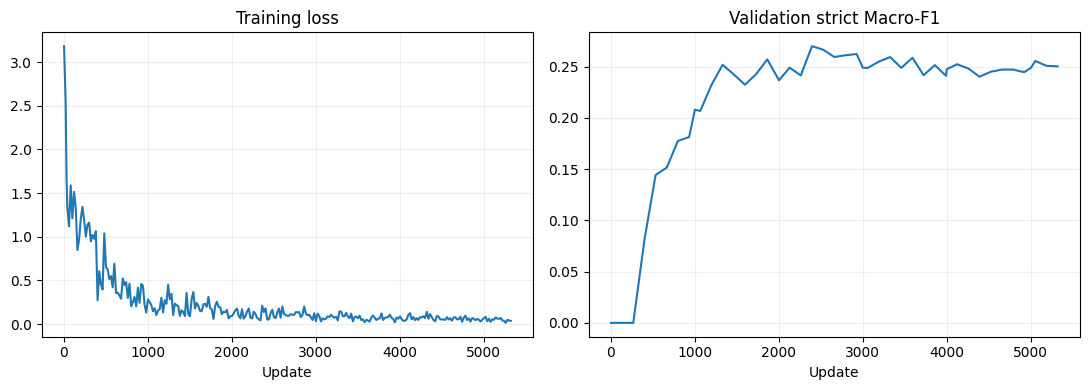

In [5]:
import matplotlib.pyplot as plt
rows=[json.loads(line) for line in (RUN_DIR/'metrics.jsonl').read_text().splitlines() if line.strip()]
fig,axes=plt.subplots(1,2,figsize=(11,4))
train=[r for r in rows if 'loss' in r]; val=[r for r in rows if 'validation_macro_f1' in r]
axes[0].plot([r['step'] for r in train],[r['loss'] for r in train]); axes[0].set_title('Training loss')
axes[1].plot([r['step'] for r in val],[r['validation_macro_f1'] for r in val]); axes[1].set_title('Validation strict Macro-F1')
for ax in axes: ax.set_xlabel('Update'); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


## F1. Evaluate the selected checkpoint

This reloads the Phase-2 `best.pt`, generates held-out predictions and runs the professor's original evaluator. It does not use Phase-1 BERTScore. Output folders are keyed by checkpoint and data hashes, so different checkpoints cannot silently share predictions.


In [6]:
def load_ner_checkpoint(path,device):
    state=torch.load(path,map_location='cpu',weights_only=False)
    signature=state['signature']; cfg=signature['config']
    if signature['labels']!=LABELS: raise ValueError('Checkpoint label order mismatch')
    if signature['tokenizer_sha256']!=digest_file(RUN_DIR/'tokenizer.json'): raise ValueError('Checkpoint tokenizer mismatch')
    model=LegalNER(signature['model'],1+2*len(LABELS),cfg,state['model']['class_weights'])
    model.load_state_dict(state['model']); model.to(device).eval()
    return model,signature

def predict_set(checkpoint_path,texts,out_root,cpu=False):
    device=torch.device('cpu' if cpu else 'cuda')
    signature=dict(checkpoint=digest_file(checkpoint_path),
        texts=hashlib.sha256(json.dumps(texts,sort_keys=True,ensure_ascii=False).encode('utf-8')).hexdigest(),
        policy='character-bio-viterbi-v3-no-trim')
    tag=hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()[:16]
    out=Path(out_root)/tag; out.mkdir(parents=True,exist_ok=True)
    if (out/'generation.json').exists() and read_json(out/'generation.json')!=signature: raise ValueError('Prediction signature mismatch')
    write_json(out/'generation.json',signature)
    predictions=read_json(out/'prediction.json') if (out/'prediction.json').exists() else {}
    if not set(predictions)<=set(texts): raise ValueError('Unknown saved document IDs')
    validate_predictions(predictions,{k:texts[k] for k in predictions},LABELS)
    model,trained=load_ner_checkpoint(checkpoint_path,device)
    try:
        for key in texts:
            if key in predictions: continue
            data=WindowData(texts,[key],TOKENIZER,trained['config'])
            verify_windows(data,texts)
            result=predict_windows(model,data,LABELS,device)
            validate_predictions(result,{key:texts[key]},LABELS)
            predictions.update(result); write_json(out/'prediction.json',predictions)
            if len(predictions)%10==0: print(f'{len(predictions)}/{len(texts)} documents',flush=True)
        validate_predictions(predictions,texts,LABELS)
        temp=out/'submission.tmp.zip'; final=out/'submission.zip'
        with zipfile.ZipFile(temp,'w',zipfile.ZIP_DEFLATED) as archive: archive.write(out/'prediction.json','prediction.json')
        with zipfile.ZipFile(temp) as archive:
            assert archive.namelist()==['prediction.json'] and archive.testzip() is None
            validate_predictions(json.loads(archive.read('prediction.json')),texts,LABELS)
        os.replace(temp,final)
        return out
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


In [7]:
NER_CHECKPOINT=RUN_DIR/'best.pt'
VAL_OUT=predict_set(NER_CHECKPOINT,{k:TEXTS[k] for k in split['val']},RUN_DIR/'validation_predictions')
command=[sys.executable,str(EVALUATOR_PATH),'--truth',str(RUN_DIR/'validation_truth.json'),
    '--prediction',str(VAL_OUT/'prediction.json'),'--labels',str(DATA_ROOT/'Train/labels.txt')]
result=subprocess.run(command,capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
(VAL_OUT/'prof_evaluation.txt').write_text(result.stdout+'\n'+result.stderr,encoding='utf-8')
write_json(VAL_OUT/'evaluator_provenance.json',dict(script_sha256=digest_file(EVALUATOR_PATH),
    truth_sha256=digest_file(RUN_DIR/'validation_truth.json'),
    prediction_sha256=digest_file(VAL_OUT/'prediction.json'),returncode=result.returncode))
result.check_returncode()
internal=span_metrics({k:GOLD[k] for k in split['val']},read_json(VAL_OUT/'prediction.json'),LABELS)
match=re.search(r'Strict Macro-F1:\s*([0-9.]+)',result.stdout)
assert match and abs(float(match.group(1))-internal['macro_f1'])<1e-6


10/10 documents
Examples: 10
APP: P=0.014706 R=0.018182 F1=0.016260
RESP: P=0.038462 R=0.107143 F1=0.056604
A.COUNSEL: P=0.200000 R=0.056604 F1=0.088235
R.COUNSEL: P=0.081967 R=0.161290 F1=0.108696
JUDGE: P=0.224490 R=0.379310 F1=0.282051
WIT: P=0.000000 R=0.000000 F1=0.000000
AUTH: P=0.216346 R=0.450000 F1=0.292208
COURT: P=0.738462 R=0.813559 F1=0.774194
STAT: P=0.276730 R=0.427184 F1=0.335878
PREC: P=0.026639 R=0.082803 F1=0.040310
DATE: P=0.831418 R=0.931330 F1=0.878543
CASENO: P=0.282443 R=0.528571 F1=0.368159
Strict Macro-F1:        0.270095
Strict Macro-Precision: 0.244305
Strict Macro-Recall:    0.329665



## F2. Official test predictions

This uses the same checkpoint and span decoder as validation. Every test document receives an entry, including an empty list when no entities are found. There is no temperature setting. Test quality cannot be scored without the private gold annotations.


In [8]:
TEST_OUT=predict_set(NER_CHECKPOINT,TEST_TEXTS,RUN_DIR/'test_predictions')
print(TEST_OUT/'submission.zip')


10/35 documents
20/35 documents
30/35 documents
/kaggle/working/phase2_model2_adapters/test_predictions/446a4dcadc8475fe/submission.zip


## F3. Download the submission

Submit only this test ZIP to Phase 2. The small-file download below embeds the archive in the notebook output. For an archive over 25 MiB, use the saved notebook version's output download instead.


In [9]:
import base64
archive=TEST_OUT/'submission.zip'
if archive.stat().st_size<=25*2**20:
    payload=base64.b64encode(archive.read_bytes()).decode('ascii')
    display(HTML(f'<a download="phase2_model2_adapters_submission.zip" href="data:application/zip;base64,{payload}">Download submission.zip</a>'))
else:
    print('Download from saved outputs:',archive)
